In [9]:
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

In [3]:
directory = "/gws/ssde/j25b/swift/gregory/histograms"

In [1]:
def get_bins(product='roa'):
    # min*x^n = max  =>  x^n = max/min  => x = (max/min)^{1/n}
    if product == 'roa':
        vmin = 0; vmax = 128; step = 0.2
        bins = np.arange(vmin,vmax+step,step)
        bins = np.append(bins,np.array((512))) # add large upper bins to capture extreme
    elif product == 'crr':
        vmin = 0; vmax = 50; step = 0.2 # step size based on CRR documentation
        bins = np.arange(vmin,vmax+step,step)
    elif product == 'mtg':
        vmin = 1e-3; vmax = 128
        nbins = 200 
        x = (vmax/vmin)**(1/nbins)
        bins = vmin*x**np.arange(0,nbins+1,1)
        bins = np.append(bins,np.array((512))) # add large upper bins to capture extreme
    return bin


WA
----------------------------------------
crr_2018_JJAS: 0 pixels
crr_2019_JJAS: 0 pixels
crr_2020_JJAS: 52711243 pixels
crr_2024_JJAS: 134548031 pixels
Total: 187259274 pixels
50th percentile: 4.90 mm/h
75th percentile: 11.10 mm/h
90th percentile: 21.90 mm/h
95th percentile: 32.30 mm/h
99th percentile: 49.90 mm/h


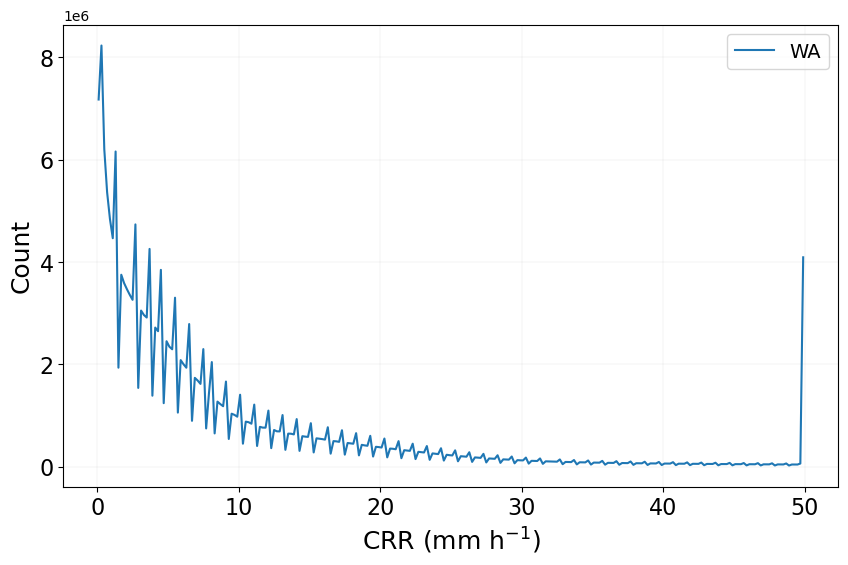


CA
----------------------------------------
crr_2018_MAM: 0 pixels
crr_2018_SON: 0 pixels
crr_2019_MAM: 0 pixels
crr_2019_SON: 0 pixels
crr_2020_MAM: 3106794 pixels
crr_2020_SON: 0 pixels
crr_2024_MAM: 284111531 pixels
crr_2024_SON: 0 pixels
Total: 287218325 pixels
50th percentile: 4.50 mm/h
75th percentile: 10.30 mm/h
90th percentile: 20.90 mm/h
95th percentile: 32.10 mm/h
99th percentile: 49.90 mm/h


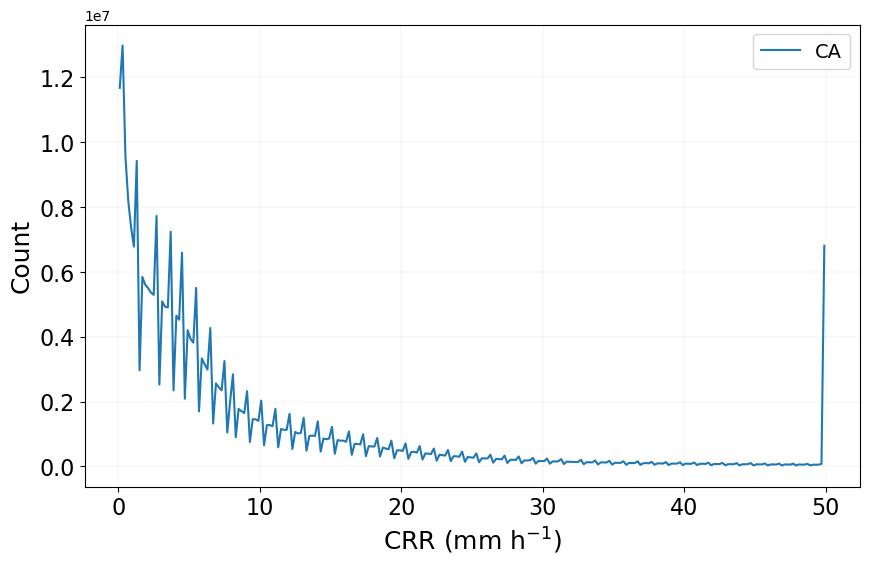


EA
----------------------------------------
crr_2018_MAM: 0 pixels
crr_2018_OND: 0 pixels
crr_2019_MAM: 0 pixels
crr_2019_OND: 0 pixels
crr_2020_MAM: 1789905 pixels
crr_2020_OND: 0 pixels
crr_2023_OND: 8077748 pixels
crr_2024_MAM: 142638077 pixels
crr_2024_OND: 0 pixels
Total: 152505730 pixels
50th percentile: 3.70 mm/h
75th percentile: 9.90 mm/h
90th percentile: 21.30 mm/h
95th percentile: 32.30 mm/h
99th percentile: 49.90 mm/h


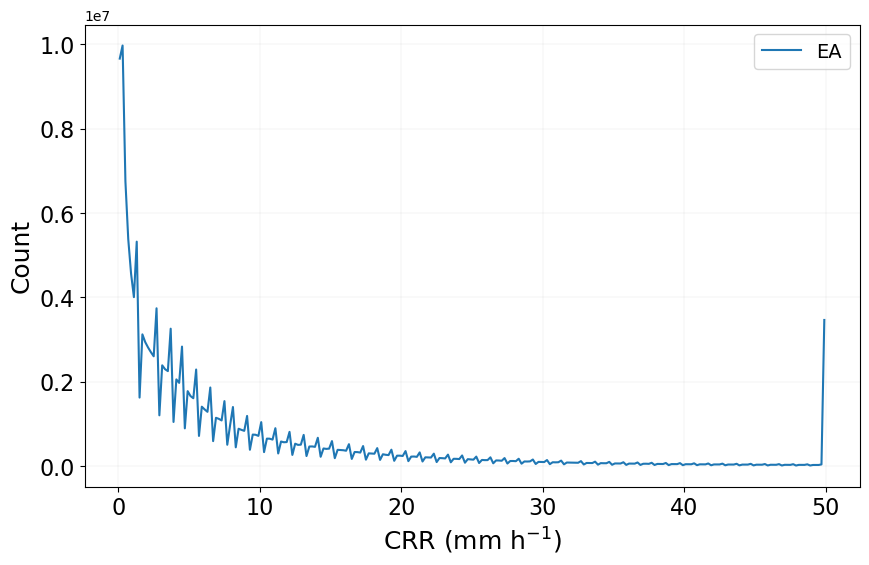


SA
----------------------------------------
crr_2018_JFMA: 0 pixels
crr_2019_JFMA: 0 pixels
crr_2019_OND: 0 pixels
crr_2020_JFMA: 0 pixels
crr_2020_OND: 0 pixels
crr_2023_OND: 58646709 pixels
crr_2024_JFMA: 296034050 pixels
crr_2024_OND: 0 pixels
Total: 354680759 pixels
50th percentile: 3.30 mm/h
75th percentile: 8.30 mm/h
90th percentile: 17.30 mm/h
95th percentile: 26.90 mm/h
99th percentile: 49.90 mm/h


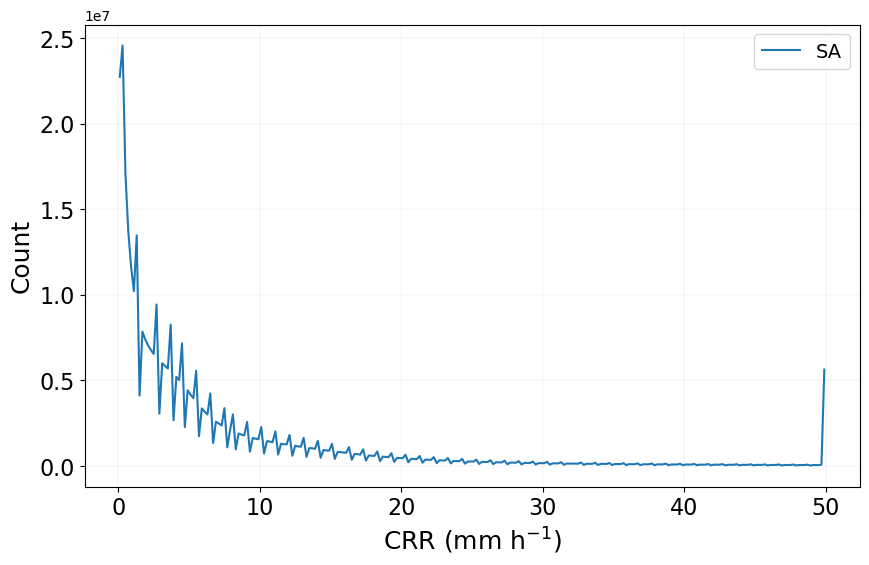

In [ ]:
base = Path("/gws/ssde/j25b/swift/gregory/histograms")

domains = ["WA", "CA", "EA", "SA"]

bins = np.arange(0, 50 + 0.2, 0.2)
bin_centres = (bins[:-1] + bins[1:]) / 2

percentiles = [50, 75, 90, 95, 99]

for domain in domains:

    files = sorted(
        (base / domain).glob("crr_*/full_hist.asc")
    )

    hist_total = np.zeros(len(bin_centres))

    print(f"\n{domain}")
    print("-" * 40)

    for path in files:

        hist = np.loadtxt(path)

        if hist.shape != (250,):
            print(
                f"Skipping {path}: "
                f"unexpected shape {hist.shape}"
            )
            continue

        hist_total += hist

        print(
            f"{path.parent.name}: "
            f"{int(hist.sum())} pixels"
        )

    if hist_total.sum() == 0:
        print("No CRR data found")
        continue

    print(
        f"Total: {int(hist_total.sum())} pixels"
    )

    cdf = np.cumsum(hist_total) / hist_total.sum()

    for percentile in percentiles:

        idx = np.searchsorted(
            cdf,
            percentile / 100
        )

        print(
            f"{percentile}th percentile: "
            f"{bin_centres[idx]:.2f} mm/h"
        )

    plt.figure(figsize=(10, 6))

    plt.plot(
        bin_centres,
        hist_total,
        label=domain
    )

    plt.xticks(fontsize=16)
    plt.yticks(fontsize=16)
    plt.legend(fontsize=14)

    plt.xlabel("CRR (mm h$^{-1}$)", fontsize=18)
    plt.ylabel("Count", fontsize=18)
    plt.grid(True, linewidth=0.1)

    plt.show()


WA
----------------------------------------
crr_2018_JJAS: 0 pixels
crr_2019_JJAS: 0 pixels
crr_2020_JJAS: 14154023 pixels
crr_2024_JJAS: 31915540 pixels
Total: 46069563 pixels
50th percentile: 5.50 mm/h
75th percentile: 15.50 mm/h
90th percentile: 34.70 mm/h
95th percentile: 49.90 mm/h
99th percentile: 49.90 mm/h


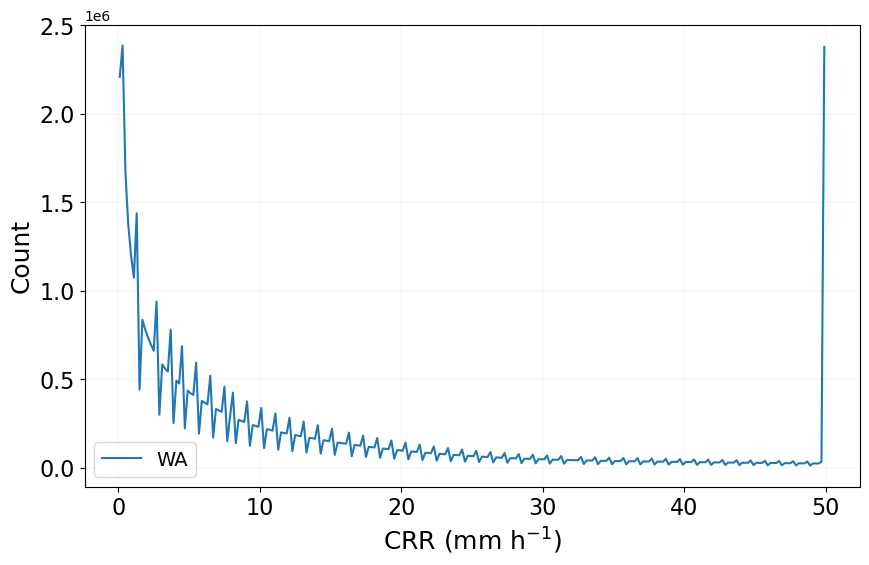


CA
----------------------------------------
crr_2018_MAM: 0 pixels
crr_2018_SON: 0 pixels
crr_2019_MAM: 0 pixels
crr_2019_SON: 0 pixels
crr_2020_MAM: 870205 pixels
crr_2020_SON: 0 pixels
crr_2024_MAM: 39383282 pixels
crr_2024_SON: 0 pixels
Total: 40253487 pixels
50th percentile: 7.50 mm/h
75th percentile: 21.30 mm/h
90th percentile: 45.30 mm/h
95th percentile: 49.90 mm/h
99th percentile: 49.90 mm/h


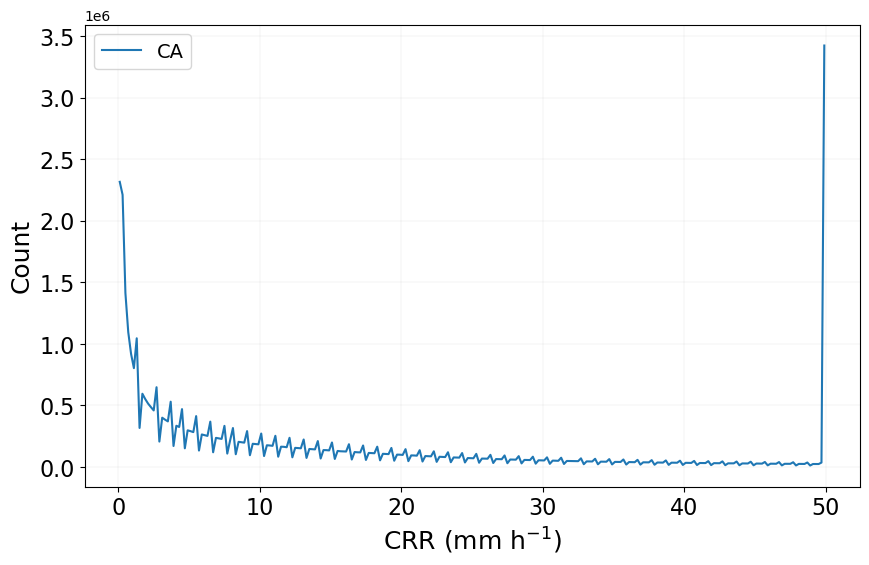


EA
----------------------------------------
crr_2018_MAM: 0 pixels
crr_2018_OND: 0 pixels
crr_2019_MAM: 0 pixels
crr_2019_OND: 0 pixels
crr_2020_MAM: 1018458 pixels
crr_2020_OND: 0 pixels
crr_2023_OND: 3058066 pixels
crr_2024_MAM: 48671355 pixels
crr_2024_OND: 0 pixels
Total: 52747879 pixels
50th percentile: 3.70 mm/h
75th percentile: 10.10 mm/h
90th percentile: 23.10 mm/h
95th percentile: 35.70 mm/h
99th percentile: 49.90 mm/h


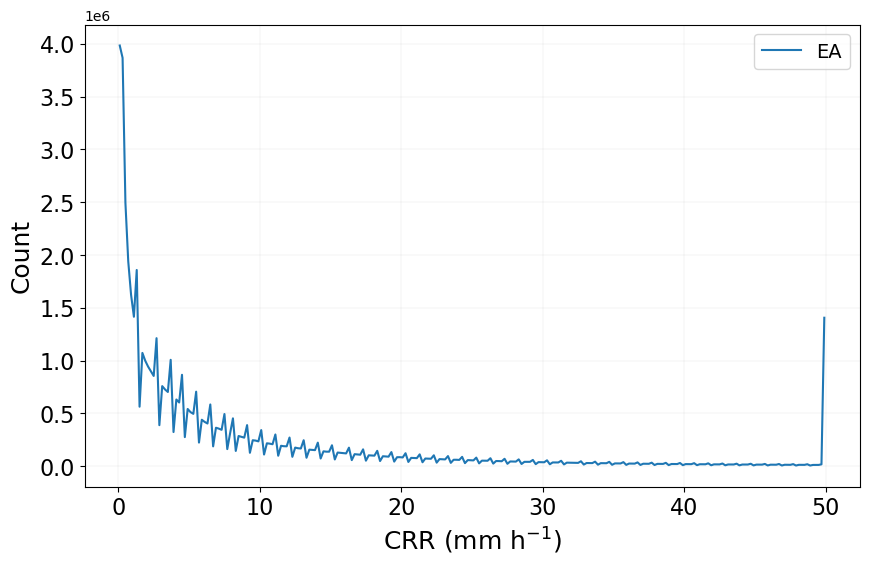


SA
----------------------------------------
crr_2018_JFMA: 0 pixels
crr_2019_JFMA: 0 pixels
crr_2019_OND: 0 pixels
crr_2020_JFMA: 0 pixels
crr_2020_OND: 0 pixels
crr_2023_OND: 13083034 pixels
crr_2024_JFMA: 63984842 pixels
crr_2024_OND: 0 pixels
Total: 77067876 pixels
50th percentile: 3.90 mm/h
75th percentile: 12.90 mm/h
90th percentile: 29.90 mm/h
95th percentile: 44.50 mm/h
99th percentile: 49.90 mm/h


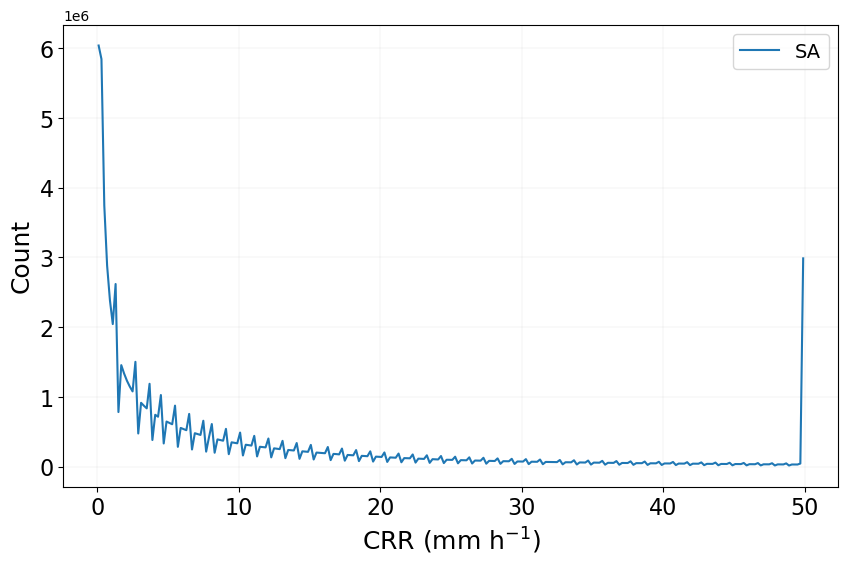

In [11]:
base = Path("/gws/ssde/j25b/swift/gregory/histograms")

domains = ["WA", "CA", "EA", "SA"]

bins = np.arange(0, 50 + 0.2, 0.2)
bin_centres = (bins[:-1] + bins[1:]) / 2

percentiles = [50, 75, 90, 95, 99]

for domain in domains:

    files = sorted(
        (base / domain).glob("crr_*/CAP_hist.asc")
    )

    hist_total = np.zeros(len(bin_centres))

    print(f"\n{domain}")
    print("-" * 40)

    for path in files:

        hist = np.loadtxt(path)

        if hist.shape != (250,):
            print(
                f"Skipping {path}: "
                f"unexpected shape {hist.shape}"
            )
            continue

        hist_total += hist

        print(
            f"{path.parent.name}: "
            f"{int(hist.sum())} pixels"
        )

    if hist_total.sum() == 0:
        print("No CRR data found")
        continue

    print(
        f"Total: {int(hist_total.sum())} pixels"
    )

    cdf = np.cumsum(hist_total) / hist_total.sum()

    for percentile in percentiles:

        idx = np.searchsorted(
            cdf,
            percentile / 100
        )

        print(
            f"{percentile}th percentile: "
            f"{bin_centres[idx]:.2f} mm/h"
        )

    plt.figure(figsize=(10, 6))

    plt.plot(
        bin_centres,
        hist_total,
        label=domain
    )

    plt.xticks(fontsize=16)
    plt.yticks(fontsize=16)
    plt.legend(fontsize=14)

    plt.xlabel("CRR (mm h$^{-1}$)", fontsize=18)
    plt.ylabel("Count", fontsize=18)
    plt.grid(True, linewidth=0.1)

    plt.show()

In [ ]:
base = Path("/gws/ssde/j25b/swift/gregory/histograms")

percentiles = {
    "WA": 98.83,
    "CA": 99.02,
    "EA": 99.70,
    "SA": 99.71,
}

bins = np.arange(0, 50 + 0.2, 0.2)

for domain, percentile in percentiles.items():

    files = sorted(
        (base / domain).glob("crr_*/full_hist.asc")
    )

    hist_total = np.zeros(len(bins) - 1)

    print(f"\n{domain}")

    for path in files:

        hist = np.loadtxt(path)

        if hist.shape != (250,):
            print(
                f"Skipping {path}: "
                f"unexpected shape {hist.shape}"
            )
            continue

        hist_total += hist

        print(f"Using: {path.parent.name}")

    if hist_total.sum() == 0:
        print("No CRR data found")
        continue

    cdf = np.cumsum(hist_total) / hist_total.sum()

    idx = np.searchsorted(
        cdf,
        percentile / 100
    )

    lower = bins[idx]
    upper = bins[idx + 1]
    centre = (lower + upper) / 2

    print(f"RoA percentile: {percentile:.2f}%")
    print(f"CRR bin: {lower:.1f}–{upper:.1f} mm/h")
    print(f"CRR threshold: {centre:.1f} mm/h")


WA
Using: crr_2018_JJAS
Using: crr_2019_JJAS
Using: crr_2020_JJAS
Using: crr_2024_JJAS
RoA percentile: 98.83%
CRR bin: 49.8–50.0 mm/h
CRR threshold: 49.9 mm/h

CA
Using: crr_2018_MAM
Using: crr_2018_SON
Using: crr_2019_MAM
Using: crr_2019_SON
Using: crr_2020_MAM
Using: crr_2020_SON
Using: crr_2024_MAM
Using: crr_2024_SON
RoA percentile: 99.02%
CRR bin: 49.8–50.0 mm/h
CRR threshold: 49.9 mm/h

EA
Using: crr_2018_MAM
Using: crr_2018_OND
Using: crr_2019_MAM
Using: crr_2019_OND
Using: crr_2020_MAM
Using: crr_2020_OND
Using: crr_2023_OND
Using: crr_2024_MAM
Using: crr_2024_OND
RoA percentile: 99.70%
CRR bin: 49.8–50.0 mm/h
CRR threshold: 49.9 mm/h

SA
Using: crr_2018_JFMA
Using: crr_2019_JFMA
Using: crr_2019_OND
Using: crr_2020_JFMA
Using: crr_2020_OND
Using: crr_2023_OND
Using: crr_2024_JFMA
Using: crr_2024_OND
RoA percentile: 99.71%
CRR bin: 49.8–50.0 mm/h
CRR threshold: 49.9 mm/h


In [14]:
from pathlib import Path
import numpy as np

base = Path("/gws/ssde/j25b/swift/gregory/histograms")

for domain in ["WA", "CA", "EA", "SA"]:

    files = sorted(
        (base / domain).glob("crr_*/CAP_hist.asc")
    )

    hist_total = np.zeros(250)

    for path in files:
        hist_total += np.loadtxt(path)

    total = hist_total.sum()

    print(f"\n{domain}")
    print(f"Total: {int(total)}")
    print(f"Last bin count: {int(hist_total[-1])}")
    print(
        f"Fraction in 49.8–50.0: "
        f"{100 * hist_total[-1] / total:.3f}%"
    )

    cdf_before_last = hist_total[:-1].sum() / total

    print(
        f"Percentile reached before final bin: "
        f"{100 * cdf_before_last:.3f}%"
    )


WA
Total: 46069563
Last bin count: 2376661
Fraction in 49.8–50.0: 5.159%
Percentile reached before final bin: 94.841%

CA
Total: 40253487
Last bin count: 3424137
Fraction in 49.8–50.0: 8.506%
Percentile reached before final bin: 91.494%

EA
Total: 52747879
Last bin count: 1405972
Fraction in 49.8–50.0: 2.665%
Percentile reached before final bin: 97.335%

SA
Total: 77067876
Last bin count: 2987095
Fraction in 49.8–50.0: 3.876%
Percentile reached before final bin: 96.124%
